# DeepInsight

In [16]:
from pyDeepInsight import ImageTransformer
from pyDeepInsight.utils import Norm2Scaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.manifold import TSNE
import pandas as pd
import numpy as np

In [ ]:
from tabular_data_to_images.common.dataset import load_dataset

## Data preprocessing
Read, normalize data and encode classes

In [18]:
X, y = load_dataset("ddos")

In [19]:
X.shape

(416, 1246)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
ln = Norm2Scaler()
X_train_norm = ln.fit_transform(X_train)
X_test_norm = ln.transform(X_test)

In [22]:
X_train_norm

array([[0.21820191, 0.13478789, 0.18269394, ..., 0.        , 0.        ,
        0.        ],
       [0.21054329, 0.18135212, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.22546395, 0.08485329, 0.20376322, ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.21907116, 0.1483125 , 0.17705954, ..., 0.        , 0.        ,
        0.        ],
       [0.2129193 , 0.09067606, 0.17630116, ..., 0.        , 0.        ,
        0.        ],
       [0.26829585, 0.23916987, 0.22369419, ..., 0.        , 0.        ,
        0.        ]])

In [23]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

In [24]:
distance_metric = 'cosine'
reducer = TSNE(
    n_components=2,
    metric=distance_metric,
    init='random',
    learning_rate='auto',
    n_jobs=-1
)

In [25]:
image_size = (30, 30)
it = ImageTransformer(
    feature_extractor=reducer, 
    pixels=image_size)

Train image transformer on training data and transform training and testing sets. Values should be between 0 and 1.

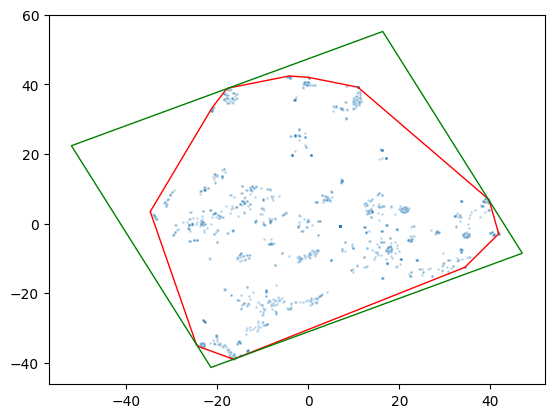

In [26]:
it.fit(X_train_norm, y=y_train, plot=True)
X_train_img = it.transform(X_train_norm)
X_test_img = it.transform(X_test_norm)

The feature density matrix can be extracted from the trained transformer in order to view overall feature overlap.

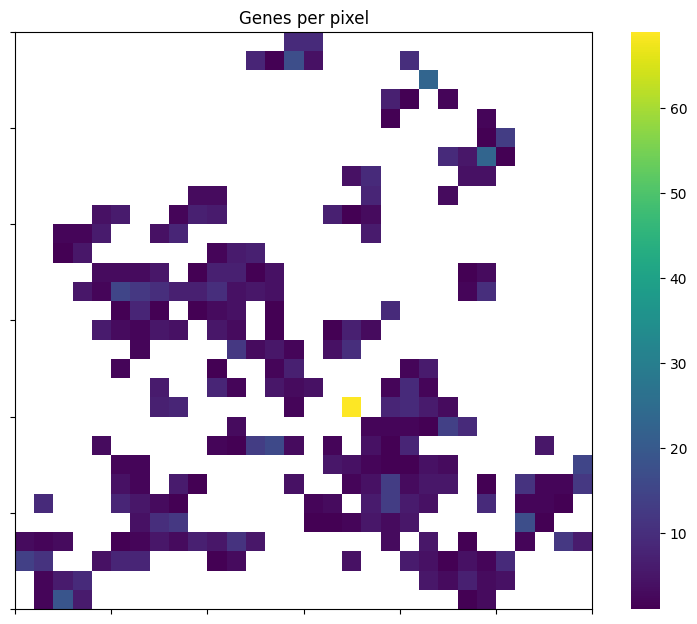

In [27]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

fdm = it.feature_density_matrix()
fdm[fdm == 0] = np.nan

plt.figure(figsize=(10, 7.5))

ax = sns.heatmap(fdm, cmap="viridis", linewidths=0., 
                 linecolor="lightgrey", square=True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
ax.yaxis.set_major_locator(ticker.MultipleLocator(5))
for _, spine in ax.spines.items():
    spine.set_visible(True)
_ = plt.title("Genes per pixel")

Plots for the image matrices first six samples of the training set.

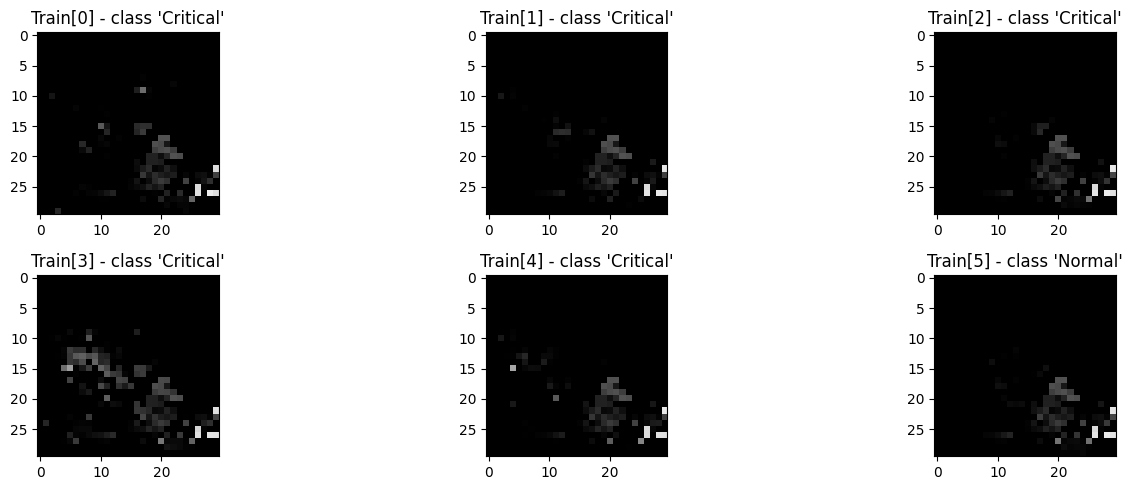

In [28]:
fig, ax = plt.subplots(2, 3, figsize=(15, 5))
ax = ax.ravel()
for i in range(6):
    ax[i].imshow(X_train_img[i])
    ax[i].title.set_text(f"Train[{i}] - class '{y_train[i]}'")
plt.tight_layout()

Plots for the image matrices first six samples of the test set.

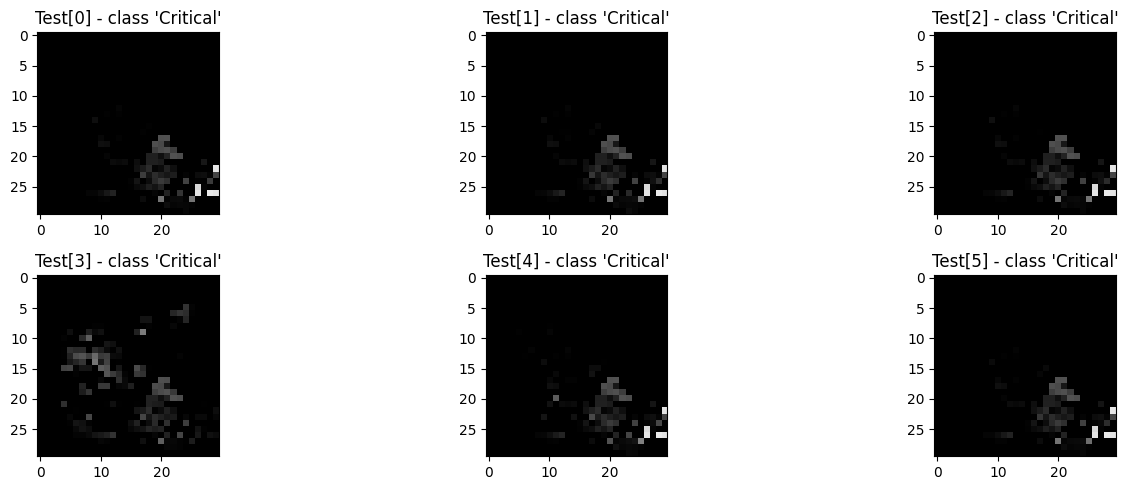

In [29]:
X_test_img = it.transform(X_test_norm)

fig, ax = plt.subplots(2, 3, figsize=(15, 5))
ax = ax.ravel()
for i in range(6):
    ax[i].imshow(X_test_img[i])
    ax[i].title.set_text(f"Test[{i}] - class '{y_test[i]}'")
plt.tight_layout()

## Fitting a CNN model

In [30]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [31]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)  # Output size: 16x15x15
        self.dropout1 = nn.Dropout(0.25)  # Dropout added for regularization
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)  # Output size: 32x7x7
        self.dropout2 = nn.Dropout(0.25)  # Another dropout layer for regularization
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.dropout1(x)
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.dropout2(x)
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [32]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
preprocess = transforms.Compose([
    transforms.ToTensor()
])
X_train_tensor = torch.stack([preprocess(img) for img in X_train_img]).float()
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.stack([preprocess(img) for img in X_test_img]).float()
y_test_tensor = torch.from_numpy(le.transform(y_test))

In [33]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [34]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-04,
    weight_decay=1e-05
)

In [35]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 0.735
[20] loss: 0.720
[40] loss: 0.673
[60] loss: 0.641
[80] loss: 0.629
[99] loss: 0.648


In [36]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.666
The test accuracy was 0.714


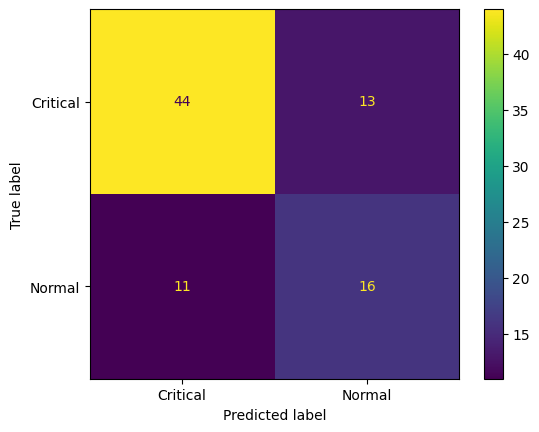

In [37]:
_ = ConfusionMatrixDisplay.from_predictions(test_predicted, y_test_tensor, display_labels=le.classes_)